In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Error: No connection selected.

In [2]:
df= pd.read_csv("titanic_cleaned_data.csv")

Error: No connection selected.

In [3]:
df

Error: No connection selected.

In [4]:

df.isnull().sum()

Error: No connection selected.

In [5]:
df.duplicated().sum(
)

Error: No connection selected.

In [6]:
X = df.drop(columns=['survived'])
y = df['survived']

Error: No connection selected.

In [ ]:
X

,pclass,sex,age,sibsp,parch,fare,class,adult_male,alone,embark_town_Queenstown,embark_town_Southampton,who_man,who_woman
0,3,1,22.000000,1,0,7.2500,1,1,0,0,1,1,0
1,1,0,38.000000,1,0,71.2833,3,0,0,0,0,0,1
2,3,0,26.000000,0,0,7.9250,1,0,1,0,1,0,1
3,1,0,35.000000,1,0,53.1000,3,0,0,0,1,0,1
4,3,1,35.000000,0,0,8.0500,1,1,1,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
775,3,0,39.000000,0,5,29.1250,1,0,0,1,0,0,1
776,1,0,19.000000,0,0,30.0000,3,0,1,0,1,0,1
777,3,0,29.699118,1,2,23.4500,1,0,0,0,1,0,1
778,1,1,26.000000,0,0,30.0000,3,1,1,0,0,1,0


In [ ]:
y


,survived
0,0
1,1
2,1
3,1
4,0
...,...
775,0
776,1
777,0
778,1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

In [ ]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
y_pred = clf.predict(X_test)

In [ ]:
clf.score(X_train, y_train)

0.8189102564102564

In [ ]:
accuracy_score(y_test, y_pred)

0.8076923076923077

In [ ]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.81      0.88      0.84        92\n           1       0.80      0.70      0.75        64\n\n    accuracy                           0.81       156\n   macro avg       0.81      0.79      0.80       156\nweighted avg       0.81      0.81      0.81       156\n'

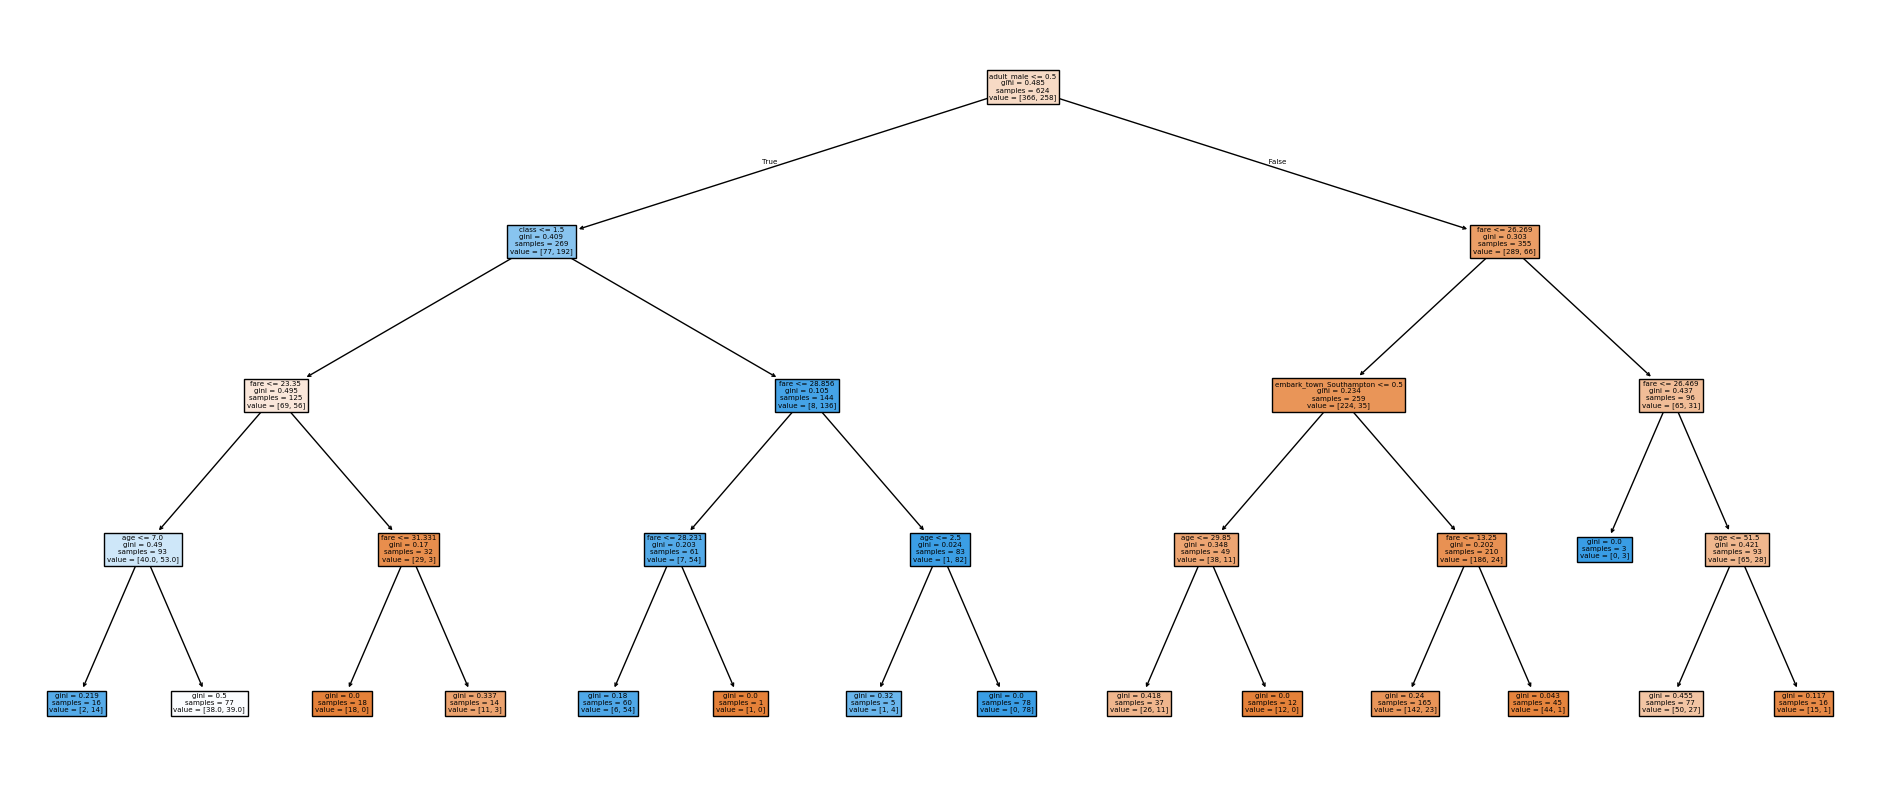

In [ ]:
plt.figure(figsize=(24,10))

tree.plot_tree(
    clf,
    filled=True,
    feature_names=X.columns
)

plt.show()

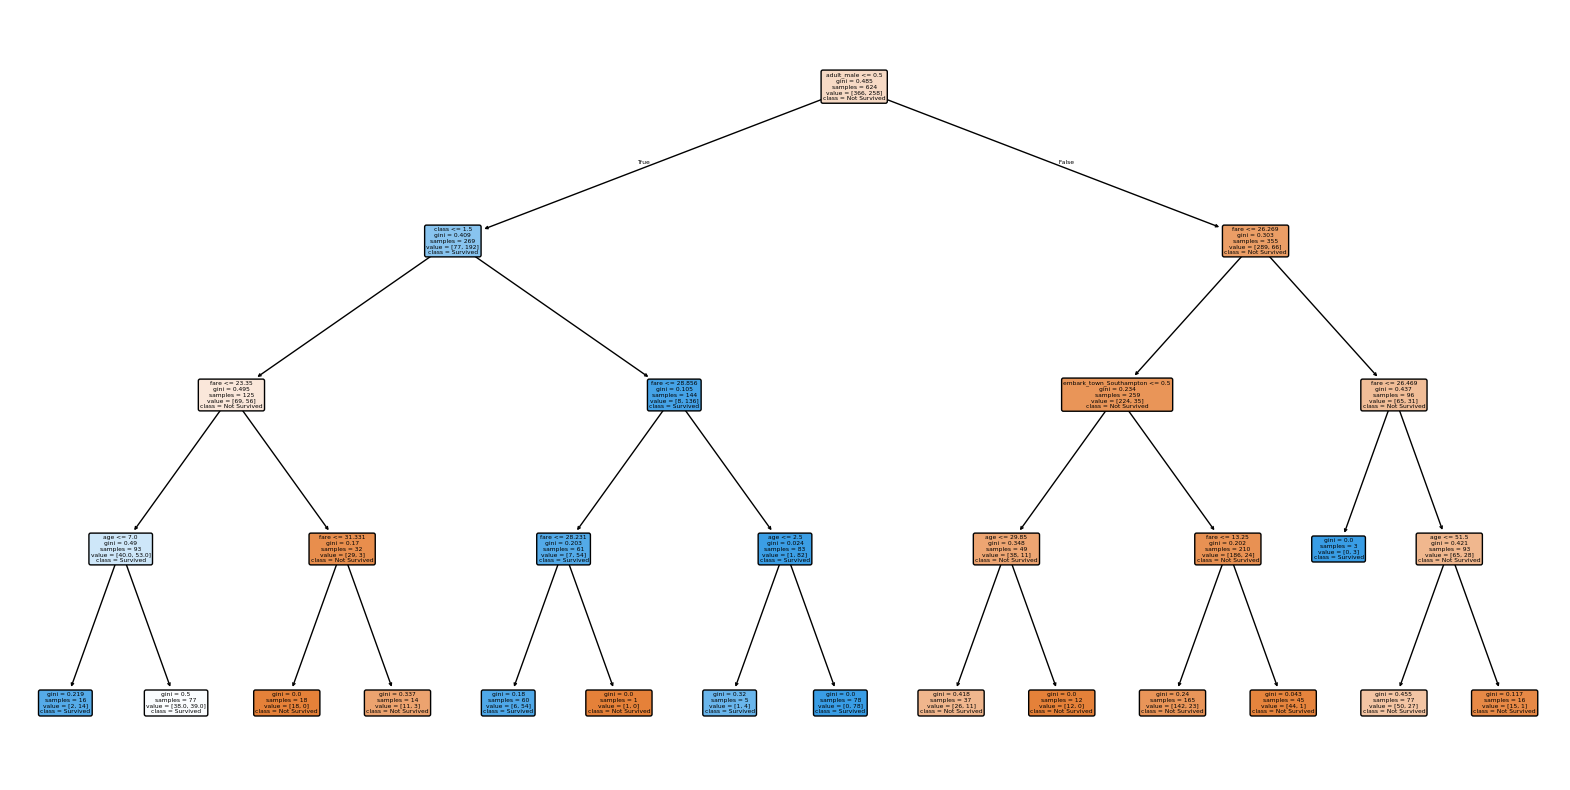

In [ ]:
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    filled=True,
    feature_names=X.columns,
    class_names=['Not Survived', 'Survived'],
    rounded=True,

)
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

In [ ]:
param = {
    'criterion': ['squared_error', 'friedman_mse', 'absolute_error'],
    'max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
    'min_samples_split': [2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 4, 6],
    'max_features': [None, 'sqrt', 'log2']
}

In [ ]:
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

In [ ]:

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['squared_error', 'friedman_mse',
                                       'absolute_error'],
                         'max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None],
                         'max_features': [None, 'sqrt', 'log2'],
                         'min_samples_leaf': [1, 2, 4, 6],
                         'min_samples_split': [2, 3, 5, 10]},
             scoring='r2')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'criterion': 'squared_error', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [ ]:

print("\nBest CV Score:")
print(grid_search.best_score_)


Best CV Score:
0.39937974649406704


In [ ]:

best_dt_random = grid_search.best_estimator_

y_pred = best_dt_random.predict(X_test)

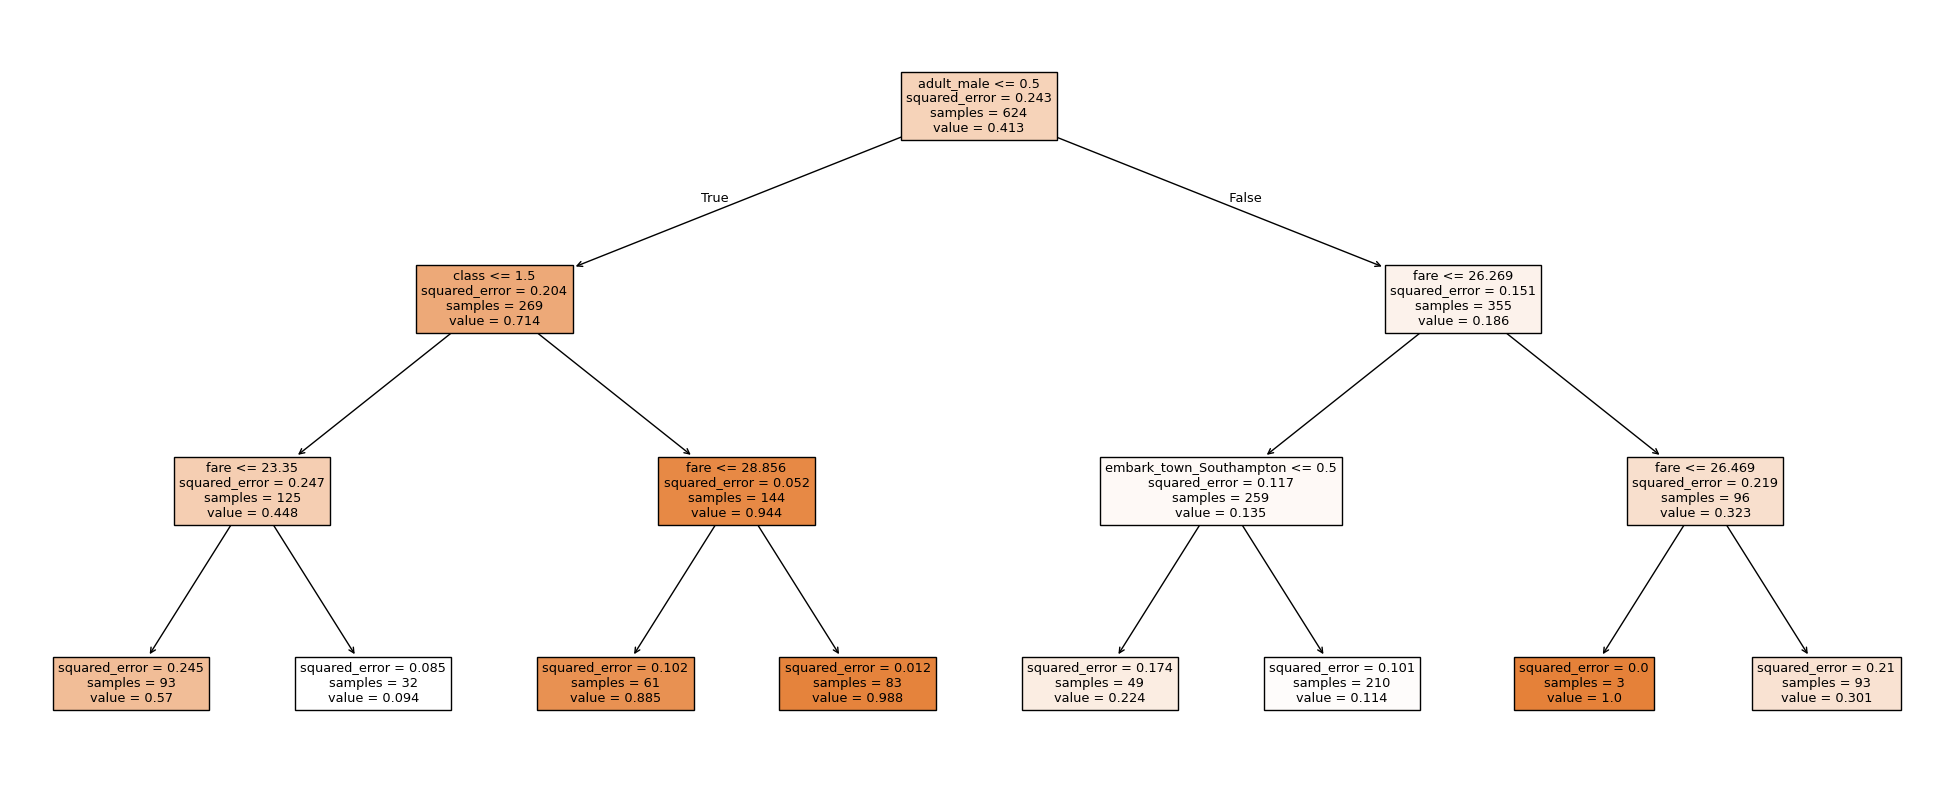

In [ ]:
plt.figure(figsize=(25,10))

tree.plot_tree(
    best_dt_random,
    filled=True,
    feature_names=X_train.columns
)

plt.show()

In [ ]:
depth=[ 1,3,7]

In [ ]:
import pickle as pkl

In [ ]:
pkl.dump(best_dt_random, open('best_model.pkl', 'wb'))